# Error analysis and robustness #
Material for the report section *Error Analysis and Robustness*. Combines the saved test forecasts of every model that
has been run (`xgboost.ipynb`, `neural_network.ipynb`, `lstm.ipynb`) on the same 10,495 test hours and breaks the errors
down by price area, hour, week, temperature and over time. Feature importance and temperature-noise sensitivity are computed
in the model notebooks (they need the trained models) and only plotted here. The test period (20 Jan - 3 Apr 2023) has no
public holidays, so holidays are scored on the validation windows (4 Dec - 14 Jan).

Figures are saved to `figures/` as PDF for `\includegraphics`.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
from forecast_checks import ForecastValidator, MakeTrainingData, load_tables

RESULTS, FIGURES = Path("results"), Path("figures")
FIGURES.mkdir(exist_ok=True)
MODELS = {"XGBoost": "xgboost", "Neural network": "neural_network", "LSTM": "lstm"}
AREAS = {"oslo": "NO1 Oslo", "stavanger": "NO2 Stavanger", "trondheim": "NO3 Trondheim", "tromsø": "NO4 Tromsø",
         "bergen": "NO5 Bergen", "helsingfors": "FI Helsingfors"}


def combine(suffix: str) -> ForecastValidator:
    """One validator with the baseline and every model whose results/<model><suffix>.json exists."""
    paths = {name: RESULTS / f"{stem}{suffix}.json" for name, stem in MODELS.items()}
    missing = [name for name, path in paths.items() if not path.exists()]
    if missing:
        print(f"Not run yet, left out: {missing}")
    loaded = {name: ForecastValidator.load_predictions(path) for name, path in paths.items() if path.exists()}
    if not loaded:
        raise FileNotFoundError(f"No results/*{suffix}.json; run the model notebooks first")
    combined = next(iter(loaded.values()))
    for name, validator in loaded.items():
        if name not in combined.forecasts:
            combined.add(name, validator.forecasts[name])   #add checks that the models were scored on the same hours
    combined.groups = combined.groups.map(AREAS).rename("Price area")
    return combined


test = combine("_predictions")
df = MakeTrainingData().df
info = df.loc[test.actual.index]
assert (info["location"].astype(str).map(AREAS) == test.groups).all()
print(f"{len(info)} test hours, {info['date'].min().date()} - {info['date'].max().date()}")
test.summary(skill=True)

10495 test hours, 2023-01-20 - 2023-04-03


,mae,rmse,nmae,bias,skill
Same hour last week,0.494720,0.806999,8.983281,0.033943,0.000000
XGBoost,0.352463,0.555389,6.400135,0.158574,0.287550
Neural network,0.257013,0.378409,4.666918,-0.001522,0.480488
LSTM,0.283851,0.415407,5.154250,0.008411,0.426240


## Per price area (table) ##
skill = 1 - MAE / MAE of the baseline, in %: above 0 is better than *same hour last week*. nMAE and bias in % of
consumption make areas of different size comparable.

In [2]:
per_area = test.per_group(skill=True)
overall = test.summary(skill=True).rename_axis("model").assign(group="All").set_index("group", append=True)
per_area_table = pd.concat([per_area, overall]).assign(skill=lambda t: 100 * t["skill"])
per_area_table = per_area_table[["mae", "nmae", "bias", "skill"]].unstack("model").reindex([*AREAS.values(), "All"])
per_area_table = per_area_table.reindex(columns=list(test.forecasts), level="model")
per_area_table.round(2)

mae                               \
model          Same hour last week XGBoost Neural network  LSTM   
group                                                             
NO1 Oslo                      1.30    0.88           0.58  0.62   
NO2 Stavanger                 0.59    0.50           0.31  0.37   
NO3 Trondheim                 0.41    0.25           0.17  0.22   
NO4 Tromsø                    0.18    0.11           0.10  0.09   
NO5 Bergen                    0.35    0.22           0.16  0.22   
FI Helsingfors                0.14    0.15           0.22  0.19   
All                           0.49    0.35           0.26  0.28   

                              nmae                               \
model          Same hour last week XGBoost Neural network  LSTM   
group                                                             
NO1 Oslo                     10.67    7.21           4.73  5.04   
NO2 Stavanger                10.51    8.92           5.42  6.57   
NO3 Trondheim                11.25    6.87           4.65  5.99   
NO4 Tromsø                    9.41    5.84           5.43  4.54   
NO5 Bergen                   10.77    6.90           4.99  6.76   
FI Helsingfors                2.12    2.29           3.51  3.02   
All                           8.98    6.40           4.67  5.15   

                              bias                               \
model          Same hour last week XGBoost Neural network  LSTM   
group                                                             
NO1 Oslo                      0.07    0.42           0.09  0.11   
NO2 Stavanger                 0.05    0.32          -0.06  0.01   
NO3 Trondheim                 0.02   -0.03           0.04 -0.12   
NO4 Tromsø                    0.00    0.05           0.01  0.01   
NO5 Bergen                    0.05    0.09          -0.03 -0.11   
FI Helsingfors                0.01    0.10          -0.05  0.15   
All                           0.03    0.16          -0.00  0.01   

                             skill                                
model          Same hour last week XGBoost Neural network   LSTM  
group                                                             
NO1 Oslo                       0.0   32.42          55.67  52.73  
NO2 Stavanger                  0.0   15.20          48.47  37.52  
NO3 Trondheim                  0.0   38.92          58.71  46.79  
NO4 Tromsø                     0.0   37.97          42.30  51.79  
NO5 Bergen                     0.0   35.95          53.67  37.19  
FI Helsingfors                 0.0   -8.12         -65.29 -42.63  
All                            0.0   28.76          48.05  42.62

In [3]:
print(per_area_table.to_latex(float_format="%.2f"))

\begin{tabular}{lrrrrrrrrrrrrrrrr}
\toprule
 & \multicolumn{4}{r}{mae} & \multicolumn{4}{r}{nmae} & \multicolumn{4}{r}{bias} & \multicolumn{4}{r}{skill} \\
model & Same hour last week & XGBoost & Neural network & LSTM & Same hour last week & XGBoost & Neural network & LSTM & Same hour last week & XGBoost & Neural network & LSTM & Same hour last week & XGBoost & Neural network & LSTM \\
group &  &  &  &  &  &  &  &  &  &  &  &  &  &  &  &  \\
\midrule
NO1 Oslo & 1.30 & 0.88 & 0.58 & 0.62 & 10.67 & 7.21 & 4.73 & 5.04 & 0.07 & 0.42 & 0.09 & 0.11 & 0.00 & 32.42 & 55.67 & 52.73 \\
NO2 Stavanger & 0.59 & 0.50 & 0.31 & 0.37 & 10.51 & 8.92 & 5.42 & 6.57 & 0.05 & 0.32 & -0.06 & 0.01 & 0.00 & 15.20 & 48.47 & 37.52 \\
NO3 Trondheim & 0.41 & 0.25 & 0.17 & 0.22 & 11.25 & 6.87 & 4.65 & 5.99 & 0.02 & -0.03 & 0.04 & -0.12 & 0.00 & 38.92 & 58.71 & 46.79 \\
NO4 Tromsø & 0.18 & 0.11 & 0.10 & 0.09 & 9.41 & 5.84 & 5.43 & 4.54 & 0.00 & 0.05 & 0.01 & 0.01 & 0.00 & 37.97 & 42.30 & 51.79 \\
NO5 Bergen & 0.35 &

## By hour of day and by weekday ##
nMAE rather than MAE, so Oslo (about 6 times the consumption of Tromsø) does not dominate.

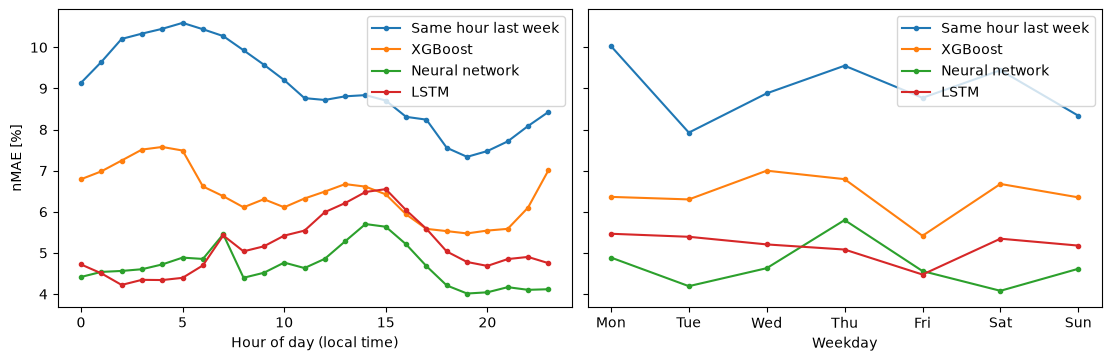

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True, layout="constrained")
test.plot_metric_by(info["hour"].rename("Hour of day (local time)"), ax=axes[0])
#From the local date, so it matches the local hour on the left. Ordered Monday - Sunday, not alphabetically
DAYS = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
weekday = pd.Series(pd.Categorical.from_codes(info["date"].dt.dayofweek, categories=DAYS), index=info.index,
                    name="Weekday")
test.plot_metric_by(weekday, ax=axes[1])
fig.savefig(FIGURES / "error_by_hour_and_weekday.pdf")

## Cold spells ##
Days are ranked by their mean temperature within each location (decile 1 = the coldest 10 % of test days there), so cold
spells in all areas are compared despite their different climates.

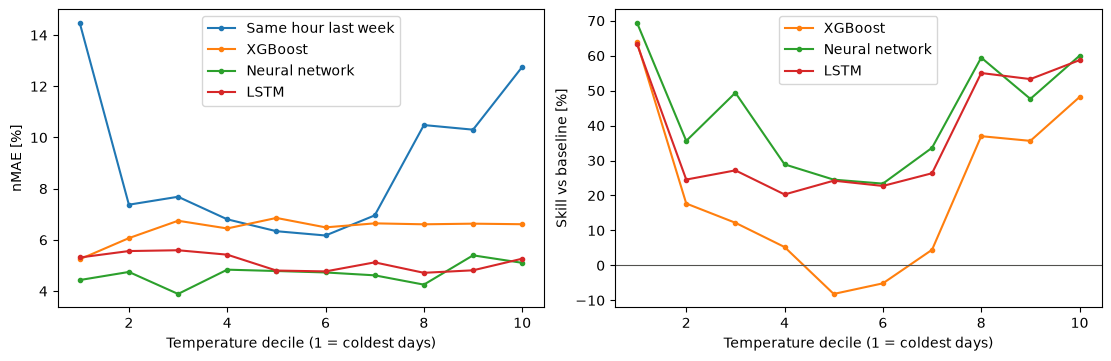

In [5]:
daily_temperature = info.groupby(["location", "date"], observed=True)["temperature"].transform("mean")
decile = (daily_temperature.groupby(info["location"], observed=True)
          .transform(lambda t: pd.qcut(t.rank(method="dense"), 10, labels=False) + 1)
          .rename("Temperature decile (1 = coldest days)"))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), layout="constrained")
test.plot_metric_by(decile, ax=axes[0])
test.plot_metric_by(decile, metric="skill", no_baseline=True, ax=axes[1])
axes[1].axhline(0, color="#52514e", linewidth=0.8)
fig.savefig(FIGURES / "error_by_temperature.pdf")

In [6]:
cold_spell = (decile == 1).map({True: "Coldest 10 % of days", False: "Other days"}).rename("period")
test.per(cold_spell, skill=True)

mae      rmse       nmae  \
model               period                                                
Same hour last week Coldest 10 % of days  0.891356  1.314524  14.476407   
                    Other days            0.445815  0.720060   8.214823   
XGBoost             Coldest 10 % of days  0.322794  0.499388   5.242460   
                    Other days            0.356121  0.561908   6.562087   
Neural network      Coldest 10 % of days  0.272851  0.425760   4.431341   
                    Other days            0.255060  0.372153   4.699874   
LSTM                Coldest 10 % of days  0.327103  0.504345   5.312436   
                    Other days            0.278518  0.403085   5.132120   

                                              bias     skill  
model               period                                    
Same hour last week Coldest 10 % of days -0.880345  0.000000  
                    Other days            0.146675  0.000000  
XGBoost             Coldest 10 % of days -0.022466  0.637862  
                    Other days            0.180897  0.201189  
Neural network      Coldest 10 % of days -0.089272  0.693892  
                    Other days            0.009298  0.427879  
LSTM                Coldest 10 % of days -0.018950  0.633028  
                    Other days            0.011784  0.375261

## Bias over time: portfolio level shifts ##
A curve that stays away from 0 for weeks means the level of the area has changed (e.g. customers gained or lost), which
consumption lags that are at least 6 days old cannot catch up with immediately.

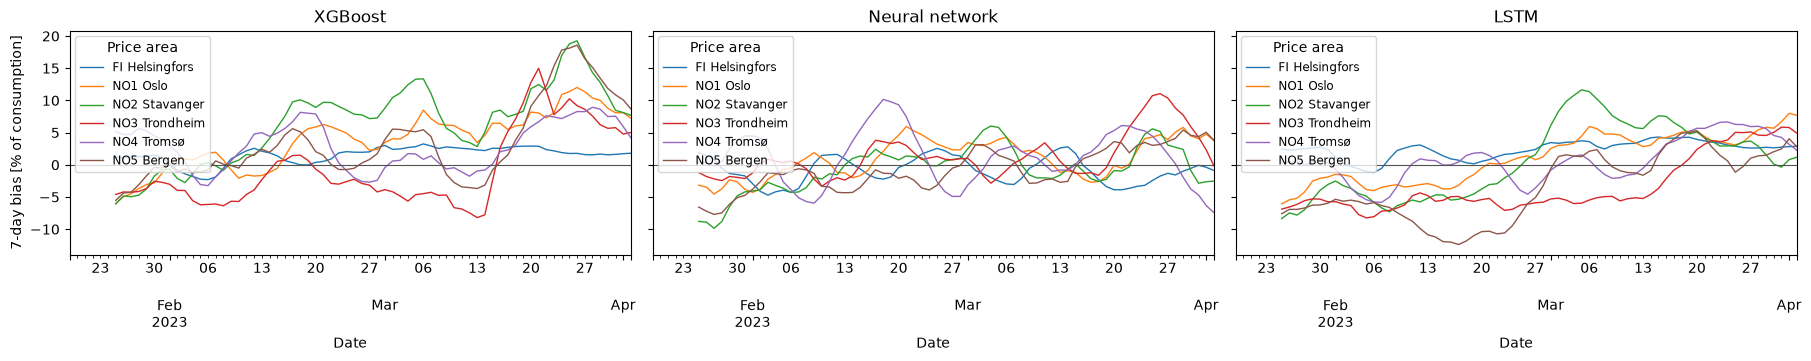

In [7]:
fig = test.plot_rolling_bias(info["time"])
fig.savefig(FIGURES / "rolling_bias.pdf")

## Feature importance and temperature forecast error ##
Left: increase in test MAE when a group of inputs is shuffled within each location. Right: increase in test MAE when a
day-ahead temperature forecast error with the given standard deviation is added (our temperature is reanalysis data,
i.e. close to the real weather).

XGBoost  Neural network       LSTM
importance [%]        consumption    20.642821      124.456268  24.386612
                      temperature    49.473069      131.898496  96.245150
                      calendar       24.896500        5.847136  53.396315
                      other weather  -0.213438        4.149717   4.701469
temperature noise [%] 0.0             0.000000        0.000000   0.000000
                      0.5             1.103457        0.768232   1.331960
                      1.0             3.292206        2.751663   4.639882
                      2.0             7.810574        9.393451  12.959033
                      3.0            13.243229       18.225456  30.011013

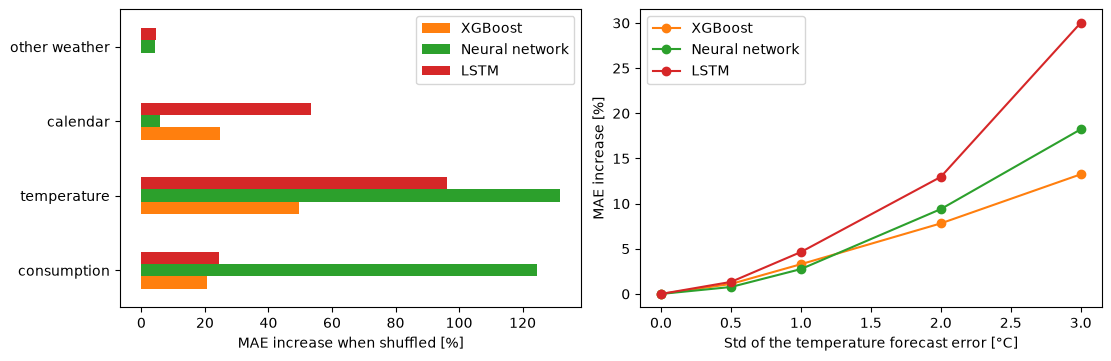

In [8]:
robustness = {name: load_tables(RESULTS / f"{stem}_robustness.json") for name, stem in MODELS.items()
              if (RESULTS / f"{stem}_robustness.json").exists()}
importance = pd.DataFrame({name: tables["importance"]["relative_increase"] for name, tables in robustness.items()})
temperature_noise = pd.DataFrame({name: tables["temperature_noise"]["relative_increase"] for name, tables in robustness.items()})

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), layout="constrained")
importance.plot.barh(ax=axes[0], color=test.colors(importance.columns))
axes[0].set_xlabel("MAE increase when shuffled [%]")
axes[0].set_ylabel("")
temperature_noise.plot(ax=axes[1], marker="o", color=test.colors(temperature_noise.columns))
axes[1].set_xlabel("Std of the temperature forecast error [°C]")
axes[1].set_ylabel("MAE increase [%]")
fig.savefig(FIGURES / "importance_and_temperature_noise.pdf")
pd.concat({"importance [%]": importance, "temperature noise [%]": temperature_noise})

## Holidays (validation windows) ##
The test period has no public holidays, so Christmas and New Year are scored on the validation windows (4 Dec - 14 Jan),
with each model fitted only on data up to 6 days before each window. Note that the neural network and the LSTM chose
their hyperparameters on these windows, so their validation scores are slightly optimistic compared with XGBoost's.

In [9]:
val = combine("_validation_predictions")
val_info = df.loc[val.actual.index]
CHRISTMAS = ("2022-12-24", "2023-01-01")
period = (val_info["date"].between(*CHRISTMAS)
          .map({True: "Christmas and New Year (24 Dec - 1 Jan)", False: "Other validation days"}).rename("period"))
val.per(period, skill=True)

mae  \
model               period                                              
Same hour last week Christmas and New Year (24 Dec - 1 Jan)  0.532187   
                    Other validation days                    0.838910   
XGBoost             Christmas and New Year (24 Dec - 1 Jan)  0.605789   
                    Other validation days                    0.669956   
Neural network      Christmas and New Year (24 Dec - 1 Jan)  0.390095   
                    Other validation days                    0.343211   
LSTM                Christmas and New Year (24 Dec - 1 Jan)  0.385428   
                    Other validation days                    0.349784   

                                                                 rmse  \
model               period                                              
Same hour last week Christmas and New Year (24 Dec - 1 Jan)  0.881321   
                    Other validation days                    1.282444   
XGBoost             Christmas and New Year (24 Dec - 1 Jan)  0.968865   
                    Other validation days                    1.035906   
Neural network      Christmas and New Year (24 Dec - 1 Jan)  0.533903   
                    Other validation days                    0.511983   
LSTM                Christmas and New Year (24 Dec - 1 Jan)  0.589194   
                    Other validation days                    0.531600   

                                                                  nmae  \
model               period                                               
Same hour last week Christmas and New Year (24 Dec - 1 Jan)   9.012042   
                    Other validation days                    14.193054   
XGBoost             Christmas and New Year (24 Dec - 1 Jan)  10.258420   
                    Other validation days                    11.334615   
Neural network      Christmas and New Year (24 Dec - 1 Jan)   6.605860   
                    Other validation days                     5.806586   
LSTM                Christmas and New Year (24 Dec - 1 Jan)   6.526829   
                    Other validation days                     5.917803   

                                                                 bias  \
model               period                                              
Same hour last week Christmas and New Year (24 Dec - 1 Jan) -0.077304   
                    Other validation days                   -0.071839   
XGBoost             Christmas and New Year (24 Dec - 1 Jan)  0.170581   
                    Other validation days                   -0.028728   
Neural network      Christmas and New Year (24 Dec - 1 Jan) -0.178362   
                    Other validation days                    0.051975   
LSTM                Christmas and New Year (24 Dec - 1 Jan) -0.258951   
                    Other validation days                   -0.127426   

                                                                skill  
model               period                                             
Same hour last week Christmas and New Year (24 Dec - 1 Jan)  0.000000  
                    Other validation days                    0.000000  
XGBoost             Christmas and New Year (24 Dec - 1 Jan) -0.138301  
                    Other validation days                    0.201397  
Neural network      Christmas and New Year (24 Dec - 1 Jan)  0.266996  
                    Other validation days                    0.590885  
LSTM                Christmas and New Year (24 Dec - 1 Jan)  0.275766  
                    Other validation days                    0.583049